# Sensitivity analyses

None of these changed a conclusion. That is the point of running them, and the
reason they are here rather than in the README.

1. Lane as a random intercept instead of a stratum
2. The denominator for viral burden
3. The infection classifier
4. Null calibration on the control elements
5. The ambiguous band between the two viral-load modes

In [1]:
import sys, pandas as pd, numpy as np
sys.path.insert(0, "../scripts")
import _common as C
pd.set_option("display.width", 200)

## 1. A lane random-intercept GLMM

Hits are called with a Mantel-Haenszel odds ratio stratified by 10x channel, i.e.
lane as a fixed effect. The alternative is to let the eight lane effects shrink
toward a common mean. `scripts/11_mixed_effects.py` fits that model per element.

In [2]:
C.read_tbl("11_glmm_summary.tsv").round(4)

,metric,value
0,elements_fitted,184.0000
1,targeting_elements,164.0000
2,pearson_r_glmm_vs_mh,0.9999
3,spearman_rho_glmm_vs_mh,0.9997
4,median_abs_difference_log_or,0.0063
5,max_abs_difference_log_or,0.0366
6,median_se_ratio_glmm_over_mh,0.9665
7,hits_mh_q<0.1,30.0000
8,hits_glmm_q<0.1,28.0000
9,hits_in_both,27.0000


Text(0.5, 1.0, 'r = 0.9999')

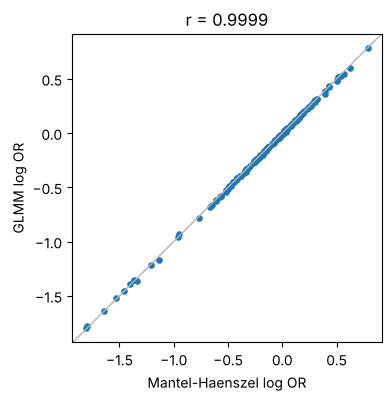

In [3]:
g = C.read_tbl("11_glmm_vs_mh.tsv")
t = g[~g.is_ntc]
ax = t.plot.scatter(x="log_or_mh", y="log_or_glmm", s=14, figsize=(4, 4))
ax.axline((0, 0), slope=1, color="0.7", lw=1); ax.set_xlabel("Mantel-Haenszel log OR")
ax.set_ylabel("GLMM log OR"); ax.set_title("r = 0.9999")

The fitted lane SD is 0.33 on the log-odds scale, so the lane effect is real. How
it is modelled is immaterial here: the lanes are large and each element's cells
are spread across all eight, so a random intercept has little to shrink. The
stratified estimator stays primary because it assumes less and because the
resampling null is built around it. The random effect is over 10x channels, not
infection experiments, so it adds no biological replication.

## 2. The denominator for viral burden

The burden model uses `log(host UMI)` as an offset. Total UMI would mean
conditioning on the outcome, since it contains the viral counts being modelled.

In [4]:
C.read_tbl("07_offset_sensitivity_summary.tsv").round(3)

,specification,n_elements_compared,spearman_vs_host_umi,pearson_vs_host_umi,top20_overlap
0,n_genes,170,0.967,0.973,16
1,total_umi,170,0.870,0.901,13
2,depth_band_no_offset,88,0.559,0.538,3


## 3. The infection classifier

Repeating the infection phenotype under a different classifier.

In [5]:
C.read_tbl("07_robustness.tsv").round(4)

,metric,value
0,effect_size_correlation_between_classifiers,0.9861
1,significant_under_both,23.0000
2,significant_under_either,31.0000
3,jaccard,0.7419


## 4. Null calibration

The control elements, run through the pipeline as if they were perturbations.

In [6]:
C.read_tbl("07_null_calibration.tsv").round(4)

,metric,value
0,ntc_elements_tested,20.0000
1,ntc_p_null_below_0.05,0.0000
2,ntc_p_null_below_0.10,0.0000
3,ntc_median_p_null,0.4373
4,ntc_glm_p_below_0.05,0.0000
5,ntc_median_glm_p,0.4159


Per phenotype: 0 of 20 controls below p = 0.1 for infection establishment, 3 of
21 for burden and 3 of 20 for the bystander ISG score, against the 2 expected
from a correctly calibrated 10% test.

## 5. The band between the two modes

9.7% of cells sit between the bystander and infected modes. `scripts/12` shows
they behave like early infection: entry-factor knockdowns deplete them, their
viral RNA is relatively richer in genomic ORF1ab than infected cells' is, and at
matched depth they carry the NF-kB / immediate-early signature without the host
shutoff. Folding them into the bystander pool, as a binary classifier must,
changes the published interferon result not at all.

In [7]:
C.read_tbl("12_borderline_composition.tsv").round(4)

,group,n_cells,viral_umi,ORF1ab,S,ORF3a,E,M,ORF6,ORF7ab,ORF8,N
0,infected,8136,22690672.0,0.0522,0.0055,0.0073,0.0052,0.0468,0.0275,0.0566,0.0317,0.7672
1,borderline,2696,232667.0,0.0771,0.0129,0.0088,0.0031,0.0381,0.0240,0.0414,0.0206,0.7741
2,bystander,17050,915507.0,0.0666,0.0117,0.0077,0.0028,0.0359,0.0231,0.0421,0.0195,0.7907


In [8]:
hr = C.read_tbl("12_borderline_host_response.tsv")
hr[["depth_bin", "median_total_umi", "host_umi_bystander", "host_umi_borderline",
    "host_umi_infected", "stress_bystander", "stress_borderline", "stress_infected"]].round(2)

,depth_bin,median_total_umi,host_umi_bystander,host_umi_borderline,host_umi_infected,stress_bystander,stress_borderline,stress_infected
0,0,2329.0,1807.0,3071.5,1651.0,0.34,1.12,2.68
1,1,5223.5,5707.0,5358.0,2719.0,0.23,0.94,4.14
2,2,8135.0,8486.0,8092.5,3326.0,0.20,0.98,4.29
3,3,11611.5,12005.0,11457.0,4355.5,0.34,0.80,4.11
4,4,16040.0,16125.0,15582.0,7374.0,0.26,0.64,3.48
5,5,20537.0,20513.0,19830.5,15909.0,0.07,0.28,2.41
6,6,24670.0,24613.5,24120.5,20902.0,-0.02,0.06,1.40
7,7,29100.5,29030.0,28249.0,25447.5,-0.11,0.24,1.04
8,8,34909.0,34833.0,33064.0,31381.0,-0.10,0.09,0.66


In [9]:
si = C.read_tbl("12_borderline_isg_sensitivity.tsv")
si[si.target.isin(["GPR89A", "KEAP1", "SPNS1", "BRD2"])][
    ["target", "population", "delta_isg", "q_null"]].round(4)

,target,population,delta_isg,q_null
18,BRD2,bystander_only,-0.3291,0.0050
89,SPNS1,bystander_only,-1.1424,0.0050
121,GPR89A,bystander_only,-1.8538,0.0050
123,KEAP1,bystander_only,-0.7395,0.0050
208,BRD2,bystander_plus_borderline,-0.2967,0.0055
284,SPNS1,bystander_plus_borderline,-1.1646,0.0055
316,GPR89A,bystander_plus_borderline,-1.8462,0.0055
318,KEAP1,bystander_plus_borderline,-0.8049,0.0055
